## Experiments: Input Features


Fahad <br>
October 30, 2026

This notebook tests how the CNN features feeding the recurrent layers affect the CNN-LSTM. Each experiment changes one parameter from the base model and compares the result on the validation set.

### How to Use This Notebook

- Build and run the base model first. Every experiment is compared with it, so it already covers the base value.
- Change one parameter at a time. Everything else stays at the base model.
- Before running an experiment, fill in the values you are testing, your hypothesis, why you chose those values, and the source that informed them.
- Judge results on validation accuracy and macro F1 only. The test set is saved for the final model.
- Fill in each results table, then the observations, insights and conclusion.

### Setup

In [30]:
import os

# Hide GPUs so everyone trains and times on CPU.
# Must run before importing TensorFlow; restart the kernel if it already was.
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

In [31]:
import copy as cp
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import display, HTML
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback
from tensorflow.keras.layers import Input, LSTM, GRU, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import f1_score

In [32]:
# Same seed as the Base Model table (8) so every team member's runs are reproducible
SEED = 8

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [33]:
# Locations of the shared data (relative to this notebook)
DATA_ROOT    = '../DATA'
FEATURE_PATH = DATA_ROOT + '/features'
MODEL_ROOT   = './models'

# Split names used in the feature file names and as dictionary keys
TRAIN      = 'train'
VALIDATION = 'val'
TEST       = 'test'


def load_data(backbone='resnet50', size=224, frames=16):
    """
    Load the precomputed CNN features and the labels for every split.

    Parameters:
        backbone: 'resnet50' or 'mobilenetv2'
        size:     input resolution the features were extracted at (224 or 112)
        frames:   frames per clip to keep (32, 16 or 8)

    Each saved clip has 32 evenly spaced frames, so fewer frames are made by
    keeping every 2nd (16) or every 4th (8) frame.

    Output:
        features: dict of float32 arrays shaped (clips, frames, feature size)
        labels:   dict of integer class labels (0-7)
    """
    step = 32 // frames
    features = {}
    labels   = {}

    # labels come from the shared splits file so everyone uses the same split
    label_data = np.load(f"{DATA_ROOT}/splits.npz")

    for name in [TRAIN, VALIDATION, TEST]:
        # features are saved as float16 to save space, so cast back for training
        x = np.load(f"{FEATURE_PATH}/{backbone}_{size}_{name}.npy").astype('float32')
        features[name] = x[:, ::step]
        labels[name]   = label_data[f'y_{name}']

    return (features, labels)


# Base model data: ResNet50, 224 px, 16 frames per clip
X, y = load_data('resnet50', 224, 16)

# Collects one row per run so the results tables can be printed
reports = []

for name in [TRAIN, VALIDATION, TEST]:
    print(name, X[name].shape, y[name].shape)

train (552, 16, 2048) (552,)
val (151, 16, 2048) (151,)
test (263, 16, 2048) (263,)


In [34]:
def config_to_html(conf):
    """Turn a run's settings dict into one compact HTML line for the 'Parameters' column."""
    items = []
    for k, v in conf.items():
        # classes such as LSTM or Adam can't be printed directly, so show their names
        if not isinstance(v, (int, float, str, tuple, list)):
            v = v.__name__
        items.append(f"{k}: {v}")
    return "<small>" + " | ".join(items) + "</small>"


def print_report(df):
    """Show a results DataFrame as a centered table with no row index."""
    styled_df = (df.style
                 # fixed decimals so the numbers don't show trailing zeros
                 .format({'Val accuracy': '{:.4f}', 'Val macro F1': '{:.4f}',
                          'Latency (ms)': '{:.1f}', 'Train time (s)': '{:.1f}'})
                 # center everything except the long Parameters text
                 .set_properties(**{'text-align': 'center'})
                 .set_properties(subset=['Parameters'], **{'text-align': 'left', 'min-width': '420px'})
                 .set_table_styles([
                     {'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold')]}
                 ]))

    # hide the row index; the method name depends on the pandas version
    try:
        styled_df = styled_df.hide_index()
    except AttributeError:
        styled_df = styled_df.hide(axis='index')

    display(HTML("<h4>Results</h4>"))
    display(styled_df)


def plot_training_history(history):
    """Plot training vs validation accuracy and loss over the epochs of one run."""
    _, axes = plt.subplots(1, 2, figsize=(12, 5))

    # left plot: accuracy
    ax = axes[0]
    ax.plot(history['accuracy'], label='Training Accuracy')
    ax.plot(history['val_accuracy'], label='Validation Accuracy')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend()

    # right plot: loss (a widening gap between the two lines means overfitting)
    ax = axes[1]
    ax.plot(history['loss'], label='Training Loss')
    ax.plot(history['val_loss'], label='Validation Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()

    plt.tight_layout()
    plt.show()

In [35]:
import time


class LatencyTracker(Callback):
    """Keras callback that records how long each training epoch takes (in seconds)."""

    def on_train_begin(self, logs=None):
        # reset the counters at the start of every fit()
        self.epoch_times = []
        self.total_epochs = 0

    def on_epoch_begin(self, epoch, logs=None):
        # start the clock for this epoch
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        # stop the clock and store how long the epoch took
        duration = time.time() - self.epoch_start_time

        self.epoch_times.append(duration)
        self.total_epochs += 1

    @property
    def total_latency(self):
        # total training time across all epochs
        return sum(self.epoch_times)

In [36]:
def create_optimizer(params):
    """Build the optimizer named in the settings dict (Adam is the base model's)."""
    if params['Optimizer'] == Adam:
        return Adam(learning_rate=params['Learning rate'])
    return None


def measure_prediction_latency(model, X_clips, n_clips=100):
    """
    Average time (ms) to predict ONE clip, the way the live demo would.
    Note: this times the recurrent part only, because the CNN features are precomputed.
    """
    clips = tf.constant(X_clips[:n_clips])
    model(clips[:1], training=False)  # warm-up call so setup time isn't counted

    start = time.time()
    for i in range(n_clips):
        model(clips[i:i + 1], training=False)  # direct call with a batch of 1 = one clip
    return (time.time() - start) / n_clips * 1000


def run_experiment(params, X, y, verbose=0, print_all=True):
    """
    Build, train and evaluate one CNN-LSTM run, then add a row to `reports`.

    params: settings dict (copy of baseline_config with one value changed)
    X, y:   feature and label dicts from load_data()
    Results are judged on the validation set only; the test set is saved for the final model.
    """
    # reset every random seed so the same settings always give the same result
    tf.keras.utils.set_random_seed(SEED)
    
    input_shape = X[TRAIN].shape[1:]  # (frames, feature size)

    # create model: recurrent layer -> dropout -> softmax output
    model = Sequential([
        Input(shape=input_shape),
        params['Recurrent layer'](params['Hidden units']),
        Dropout(params['Droupout rate']),
        Dense(params['Output'][0], activation=params['Output'][1])
    ])

    # compile model
    model.compile(
        optimizer=create_optimizer(params),
        loss=params['Loss'],
        metrics=params['Metrics']
    )

    model.summary()

    # early stopping watches the validation loss and keeps the best weights
    early_stopping = EarlyStopping(monitor=params['Moniter'],
                                   patience=params['patience'],
                                   restore_best_weights=params['restore best weights'])

    # records how long each epoch takes
    latency_tracker = LatencyTracker()

    history = model.fit(X[TRAIN], y[TRAIN],
                        validation_data=(X[VALIDATION], y[VALIDATION]),
                        epochs=params['Epochs'],
                        batch_size=params['Batch size'],
                        callbacks=[early_stopping, latency_tracker],
                        verbose=verbose)

    # validation metrics for the report
    val_loss, val_accuracy = model.evaluate(X[VALIDATION], y[VALIDATION], verbose=0)
    y_val_pred = np.argmax(model.predict(X[VALIDATION], verbose=0), axis=1)  # predicted class per clip
    val_f1 = f1_score(y[VALIDATION], y_val_pred, average=params['F1 Average'])

    report = {
        'Val accuracy': round(val_accuracy, 4),
        'Val macro F1': round(val_f1, 4),
        'Epochs run': len(history.history['loss']),  # one loss value is stored per epoch
        'Parameters': config_to_html(params),
        'Latency (ms)': round(measure_prediction_latency(model, X[VALIDATION]), 1),
        'Train time (s)': round(latency_tracker.total_latency, 1)
    }

    # add this run to the running results table
    report_ext = {
        'Run': params['Experiment Name'],
        'Setting': params['Setting']
    }
    report_ext.update(report)
    reports.append(report_ext)

    if print_all:
        print_report(pd.DataFrame(reports))
    else:
        print_report(pd.DataFrame([report]))
    plot_training_history(history.history)

### Base Model

| Parameter | Base model |
|---|---|
| Backbone | ResNet50 (frozen, ImageNet weights) |
| Input resolution | 224 px |
| Frames per clip | 16 |
| Recurrent layer type | LSTM |
| Hidden units | 256 |
| Number of recurrent layers | 1 |
| Dropout placement | After the LSTM |
| Dropout rate | 0.5 |
| Output | Dense(8, softmax) |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss | Sparse categorical cross-entropy |
| Batch size | 32 |
| Epochs | Up to 100, early stopping on val loss (patience 8, restore best weights) |
| Seed | 8 |

In [37]:
# Base model settings (same as the Base Model table above).
# Each experiment copies this dict and changes one value.
baseline_config = {}
baseline_config['Experiment Name'] = "base"
baseline_config['Setting'] = "-"

baseline_config['Recurrent layer'] = LSTM
baseline_config['Hidden units']    = 256
baseline_config['Droupout rate']   = 0.5
baseline_config['Output']          = (8, "softmax")   # 8 exercise classes
baseline_config['Optimizer']       = Adam
baseline_config['Learning rate']   = 0.001
baseline_config['Loss']            = "sparse_categorical_crossentropy"
baseline_config['Metrics']         = ["accuracy"]
baseline_config['Batch size']      = 32
baseline_config['Epochs']          = 100               # upper limit; early stopping ends it sooner
baseline_config['F1 Average']      = "macro"
baseline_config['Moniter']         = "val_loss"        # early stopping watches validation loss
baseline_config['patience']        = 8
baseline_config['restore best weights'] = True

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_9 (LSTM)               (None, 256)               2360320   
                                                                 
 dropout_9 (Dropout)         (None, 256)               0         
                                                                 
 dense_9 (Dense)             (None, 8)                 2056      
                                                                 
Total params: 2,362,376
Trainable params: 2,362,376
Non-trainable params: 0
_________________________________________________________________
Epoch 1/100
18/18 [==============================] - 7s 288ms/step - loss: 1.4592 - accuracy: 0.5036 - val_loss: 1.7604 - val_accuracy: 0.3974
Epoch 2/100
18/18 [==============================] - 4s 245ms/step - loss: 0.5872 - accuracy: 0.8460 - val_loss: 1.6607 - val_accuracy: 0.4238
Epoch 3/100
18/18 [===

Val accuracy,Val macro F1,Epochs run,Parameters,Latency (ms),Train time (s)
0.4901,0.5268,11,"Experiment Name: base | Setting: - | Recurrent layer: LSTM | Hidden units: 256 | Droupout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Moniter: val_loss | patience: 8 | restore best weights: True",34.1,59.5


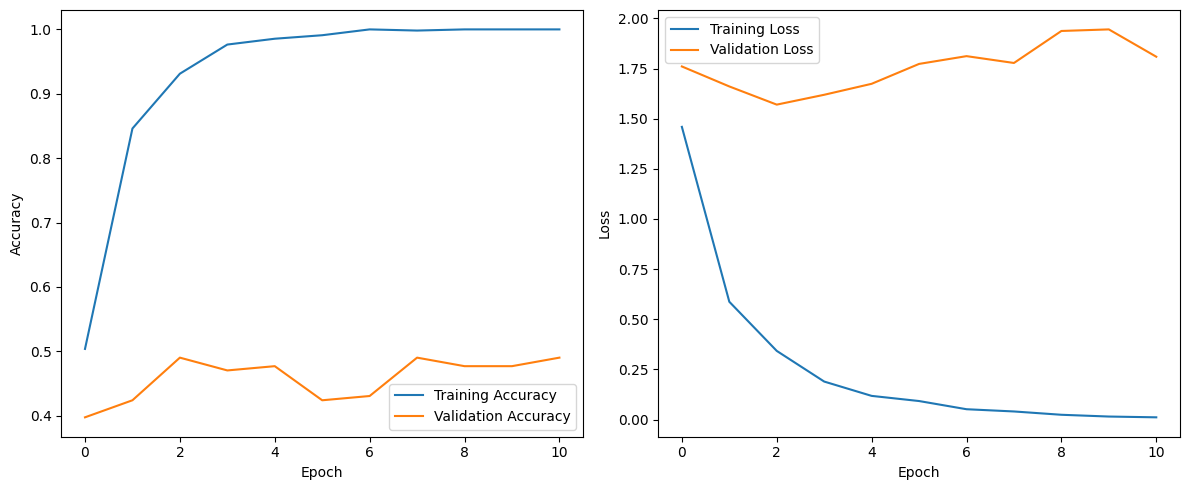

In [38]:
# Train and evaluate the base model: ResNet50, 224 px, 16 frames, LSTM 256
run_experiment(baseline_config, X, y, verbose=1, print_all=False)

#### Results

| Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|
| 0.4901 | 0.5268 | 11 (best epoch 3) | 2,362,376 | 34.1 |

### Backbone

| Parameter | Base model | Testing |
|---|---|---|
| Backbone | ResNet50 | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Input Resolution

| Parameter | Base model | Testing |
|---|---|---|
| Input resolution | 224 px | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Frames per Clip

| Parameter | Base model | Testing |
|---|---|---|
| Frames per clip | 16 | 8 and 32 |

**Hypothesis:** I expect 8 frames to run faster but score slightly lower, because a short sequence can miss part of the movement (for example the bottom of a squat or the push-off of a jumping jack). I expect 32 frames to give little or no gain in accuracy and macro F1, and to roughly double the prediction time because the LSTM has twice as many steps. The base model already overfits (100% training accuracy against about 48% validation), so extra frames are more likely to add redundant detail than useful information.

**Why these values:** Each clip is stored as 32 frames spread evenly across the whole clip. That gives three natural settings without re-extracting anything: all 32 frames, every 2nd frame (16, the base model) or every 4th frame (8). In every setting the frames still cover the full movement from start to finish, so only the time resolution changes. These are also the values in our proposal's experiment table.

**Source:** Group proposal (experiment table: more frames add temporal detail but cost speed); Donahue et al. (2015), which feeds a sequence of frame features into an LSTM, so the number of frames is the length of that sequence.

Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_10 (LSTM)              (None, 256)               2360320   
                                                                 
 dropout_10 (Dropout)        (None, 256)               0         
                                                                 
 dense_10 (Dense)            (None, 8)                 2056      
                                                                 
Total params: 2,362,376
Trainable params: 2,362,376
Non-trainable params: 0
_________________________________________________________________


Run,Setting,Val accuracy,Val macro F1,Epochs run,Parameters,Latency (ms),Train time (s)
base,-,0.4901,0.5268,11,"Experiment Name: base | Setting: - | Recurrent layer: LSTM | Hidden units: 256 | Droupout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Moniter: val_loss | patience: 8 | restore best weights: True",34.1,59.5
1,Frames per clip => 8,0.3709,0.4199,11,"Experiment Name: 1 | Setting: Frames per clip => 8 | Recurrent layer: LSTM | Hidden units: 256 | Droupout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Moniter: val_loss | patience: 8 | restore best weights: True",23.2,24.7


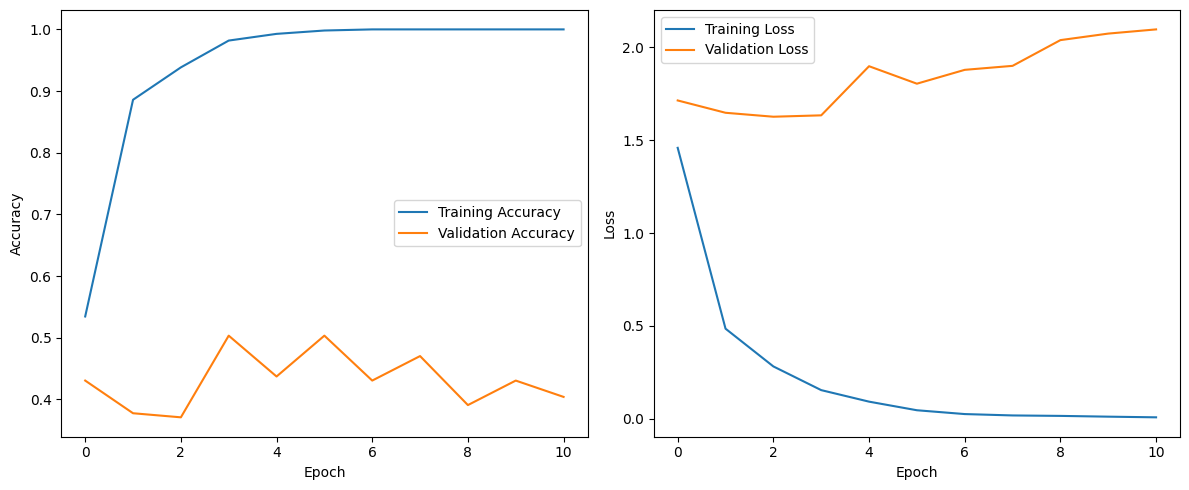

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_11 (LSTM)              (None, 256)               2360320   
                                                                 
 dropout_11 (Dropout)        (None, 256)               0         
                                                                 
 dense_11 (Dense)            (None, 8)                 2056      
                                                                 
Total params: 2,362,376
Trainable params: 2,362,376
Non-trainable params: 0
_________________________________________________________________


Run,Setting,Val accuracy,Val macro F1,Epochs run,Parameters,Latency (ms),Train time (s)
base,-,0.4901,0.5268,11,"Experiment Name: base | Setting: - | Recurrent layer: LSTM | Hidden units: 256 | Droupout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Moniter: val_loss | patience: 8 | restore best weights: True",34.1,59.5
1,Frames per clip => 8,0.3709,0.4199,11,"Experiment Name: 1 | Setting: Frames per clip => 8 | Recurrent layer: LSTM | Hidden units: 256 | Droupout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Moniter: val_loss | patience: 8 | restore best weights: True",23.2,24.7
2,Frames per clip => 32,0.5364,0.5348,11,"Experiment Name: 2 | Setting: Frames per clip => 32 | Recurrent layer: LSTM | Hidden units: 256 | Droupout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Moniter: val_loss | patience: 8 | restore best weights: True",56.0,106.8


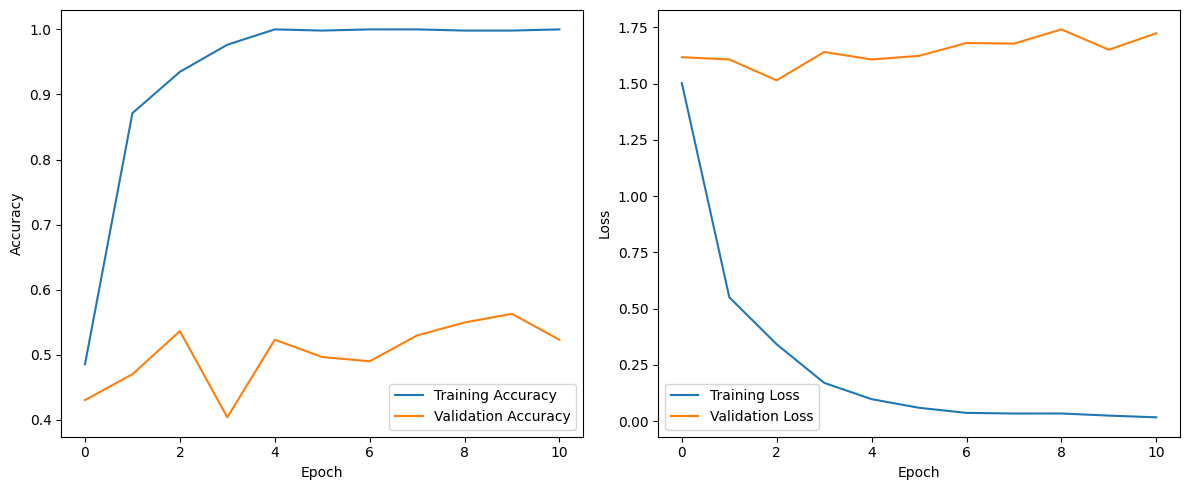

In [39]:
# Experiment 1: 8 frames per clip (every 4th saved frame)
X_8, y_8 = load_data('resnet50', 224, 8)

test_conf_1 = cp.deepcopy(baseline_config)   # start from the base model settings
test_conf_1['Experiment Name'] = "1"
test_conf_1['Setting'] = "Frames per clip => 8"

run_experiment(test_conf_1, X_8, y_8)


# Experiment 2: 32 frames per clip (all saved frames)
X_32, y_32 = load_data('resnet50', 224, 32)

test_conf_2 = cp.deepcopy(baseline_config)
test_conf_2['Experiment Name'] = "2"
test_conf_2['Setting'] = "Frames per clip => 32"

run_experiment(test_conf_2, X_32, y_32)

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | 16 frames | 0.4901 | 0.5268 | 11 (best epoch 3) | 2,362,376 | 34.1 |
| 1 | 8 frames | 0.3709 | 0.4199 | 11 (best epoch 3) | 2,362,376 | 23.2 |
| 2 | 32 frames | 0.5364 | 0.5348 | 11 (best epoch 3) | 2,362,376 | 56.0 |

#### Observations

- **8 frames was clearly worse than the base model.** Validation accuracy fell from 0.4901 to 0.3709 (about 12 points) and macro F1 from 0.5268 to 0.4199 (about 11 points).
- **32 frames was the best on accuracy.** It reached 0.5364 (+4.6 points over the base), but macro F1 barely moved (0.5348 vs 0.5268, +0.8 points).
- **Prediction time grew with the number of frames.** Predicting one clip took 23.2 ms at 8 frames, 34.1 ms at 16 and 56.0 ms at 32, which is about 1.4 ms per added frame. Going to 32 frames made prediction about 64% slower than the base, and 8 frames made it about 32% faster. All three are far below the 0.5 s limit.
- **Training time grew even faster:** 24.7 s at 8 frames, 59.5 s at 16 and 106.8 s at 32.
- **Every run overfit in the same way.** Training accuracy reached 100% within about 6 to 8 epochs, while validation accuracy stayed between 0.37 and 0.54. The best validation loss came at epoch 3 in all three runs, and early stopping ended each one at epoch 11.
- **No setting came close to the 88% accuracy target.**
- **The ordering 8 < 16 < 32 held in every run we did,** including earlier runs made before the seed was fixed. In those, 8 frames scored between 0.36 and 0.44, 16 frames between 0.48 and 0.50, and 32 frames between 0.51 and 0.54. Because the validation set is small (151 clips), differences of a few points between single runs should be treated with caution, and the 16 to 32 gap is small enough to be partly noise.

#### Insights

- **Why fewer frames hurt:** each clip is sampled evenly over its whole length, so using 8 frames leaves large time gaps between frames. Several of our classes are fast, repeating movements (jumping jacks, jump rope), and a sparse sample can miss part of a cycle or catch it at misleading moments. Classes that differ mainly by motion rather than appearance (squats vs lunges, push-ups vs wall push-ups) also depend on seeing enough of the movement. The LSTM can only learn movement from the frames it is given, so 8 frames is probably too few. A per-class check on the confusion matrix would confirm which exercises lost the most.
- **Why 32 frames gained so little over 16:** frames that are only a fraction of a second apart look almost the same, so their ResNet50 feature vectors are nearly identical. Going from 16 to 32 mostly adds repeated information, not new movement, which fits the small macro F1 gain (+0.8 points).
- **The real bottleneck is overfitting, not temporal detail:** the LSTM has about 2.4 million trainable parameters but only 552 training clips. It reaches 100% training accuracy while validation stays around 50%, so it memorizes the training clips. UCF101 clips from the same group share a person and background, and our split keeps whole groups apart, so the validation clips show new people and scenes. The frozen ImageNet features describe what is in each frame, not how it moves, so the model leans on appearance that does not carry over to new groups. This is the overfitting and early stopping behaviour we saw in class, and changing the number of frames does not fix it. That is why every setting peaks at epoch 3 and stays far below the 88% target.
- **Why speed scales with frames:** an LSTM reads one frame at a time and each step depends on the previous one, so prediction time grows in a straight line with the number of frames (about 1.4 ms per frame). Training is slower still because the model also has to backpropagate through every step.
- **Live-demo caveat:** these timings cover the LSTM only, because the CNN features were computed ahead of time. In the live demo, ResNet50 has to process every frame, so 32 frames means twice as many ResNet50 runs as 16 frames. That cost will likely be much larger than the LSTM time here, and it has not been measured yet.

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| 32 frames (provisional) | Yes, pending the CNN timing | Highest validation accuracy (0.5364 vs 0.4901 for the base) and slightly higher macro F1 (0.5348 vs 0.5268), so it counts as an improvement under our rule, and its LSTM prediction time (56 ms) is far under 0.5 s. The gain over 16 frames is small, though, and 32 frames doubles the ResNet50 work per prediction in the live demo, which we have not timed. 8 frames is clearly worse (0.3709) and is not carried forward. |

### Soft Voting

| Parameter | Base model | Testing |
|---|---|---|
| Soft voting | Off | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Summary

| Experiment | Best value | Carry forward? | Reason |
|---|---|---|---|
| Backbone | | | |
| Input Resolution | | | |
| Frames per Clip | | | |
| Soft Voting | | | |

#### Overall Conclusions

_What should the final model use, and what did these experiments show about the problem?_